# 02 – Datenaufbereitung & Integration in SQLite
Ziel: die drei Quellen zu **einer Analysetabelle** `analyse` verknüpfen und jeden Schritt (verlorene/gewonnene Datensätze) dokumentieren.

| Verknüpfung | Schlüssel | Problem / Lösung |
|---|---|---|
| Ist-Daten ↔ Stationen | `bpuic` (7-stellige Haltestellennummer) | Ist-Daten enthalten 7-, 9-stellige Nummern und SLOIDs → beim Laden auf 7 Stellen vereinheitlicht |
| Ist-Daten ↔ Wetter | `bpuic` + Stunde der Soll-Ankunft | Wetter in Stundenauflösung → Ankunftszeit auf volle Stunde abgerundet; Zeitumstellung (doppelte Stunde) → erste Messung |

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config
from src.db import get_connection

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config.OUTPUT_DIR.mkdir(exist_ok=True)
conn = get_connection()
print("Datenbank:", config.DB_PATH)

Datenbank: /Users/ayushanahilan/Documents/5. Semester/DataAnalytics/DataAnalytics_Gruppe37/data/zugverspaetung.sqlite


## 1. Datenqualität der Rohdaten (Tabelle `halte`)

In [2]:
qualitaet = pd.read_sql("""
    SELECT an_status,
           COUNT(*) AS anzahl,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM halte WHERE ankunft_soll IS NOT NULL), 1) AS prozent
    FROM halte
    WHERE ankunft_soll IS NOT NULL
    GROUP BY an_status ORDER BY anzahl DESC""", conn)
display(qualitaet)

display(pd.read_sql("""
    SELECT COUNT(*) AS anzahl_halte,
           SUM(faellt_aus) AS ausgefallen,
           SUM(CASE WHEN an_delay_min < -10 OR an_delay_min > 180 THEN 1 ELSE 0 END) AS unplausible_verspaetung,
           SUM(CASE WHEN ankunft_soll IS NULL THEN 1 ELSE 0 END) AS ohne_ankunft_startbahnhof
    FROM halte""", conn))

duplikate = pd.read_sql("""
    SELECT COUNT(*) AS gruppen_mit_duplikaten FROM (
        SELECT betriebstag, fahrt_id, bpuic, COUNT(*) AS n FROM halte
        WHERE ankunft_soll IS NOT NULL
        GROUP BY 1, 2, 3 HAVING n > 1)""", conn)
display(duplikate)

,an_status,anzahl,prozent
0,REAL,1768277,93.3
1,UNKNOWN,73927,3.9
2,FORECAST,53613,2.8


,anzahl_halte,ausgefallen,unplausible_verspaetung,ohne_ankunft_startbahnhof
0,2078429,62995,491,182612


,gruppen_mit_duplikaten
0,763


## 2. Integrations-Trichter: wie viele Datensätze bleiben pro Schritt?

In [3]:
schritte = {
    "1 Alle Zug-Halte (Schweiz)":                 "SELECT COUNT(*) FROM halte",
    "2 mit Soll-Ankunft (kein Startbahnhof)":     "SELECT COUNT(*) FROM halte WHERE ankunft_soll IS NOT NULL",
    "3 nicht ausgefallen":                         "SELECT COUNT(*) FROM halte WHERE ankunft_soll IS NOT NULL AND faellt_aus = 0",
    "4 gemessene Ist-Zeit (Status REAL)":         "SELECT COUNT(*) FROM halte WHERE ankunft_soll IS NOT NULL AND faellt_aus = 0 AND an_status = 'REAL'",
    "5 plausible Verspätung (-10 bis 180 min)":   "SELECT COUNT(*) FROM halte WHERE ankunft_soll IS NOT NULL AND faellt_aus = 0 AND an_status = 'REAL' AND an_delay_min BETWEEN -10 AND 180",
    "6 Join mit Stationen (Koordinaten/Region)":  """SELECT COUNT(*) FROM halte h JOIN stationen s ON s.bpuic = h.bpuic
                                                    WHERE h.ankunft_soll IS NOT NULL AND h.faellt_aus = 0 AND h.an_status = 'REAL' AND h.an_delay_min BETWEEN -10 AND 180""",
    "7 Join mit Wetter (Top-Bahnhöfe)":           """SELECT COUNT(*) FROM halte h JOIN stationen s ON s.bpuic = h.bpuic
                                                    JOIN wetter w ON w.bpuic = h.bpuic AND w.zeit = strftime('%Y-%m-%d %H:00', h.ankunft_soll)
                                                    WHERE h.ankunft_soll IS NOT NULL AND h.faellt_aus = 0 AND h.an_status = 'REAL' AND h.an_delay_min BETWEEN -10 AND 180""",
}
trichter = pd.DataFrame({"schritt": list(schritte),
                         "datensaetze": [conn.execute(q).fetchone()[0] for q in schritte.values()]})
trichter["verlust_zum_vorschritt"] = trichter["datensaetze"].diff().fillna(0).astype(int)
trichter["anteil_von_start_%"] = (100 * trichter["datensaetze"] / trichter["datensaetze"].iloc[0]).round(1)
display(trichter)

,schritt,datensaetze,verlust_zum_vorschritt,anteil_von_start_%
0,1 Alle Zug-Halte (Schweiz),2078429,0,100.0
1,2 mit Soll-Ankunft (kein Startbahnhof),1895817,-182612,91.2
2,3 nicht ausgefallen,1840569,-55248,88.6
3,4 gemessene Ist-Zeit (Status REAL),1768277,-72292,85.1
4,5 plausible Verspätung (-10 bis 180 min),1767800,-477,85.1
5,6 Join mit Stationen (Koordinaten/Region),1767800,0,85.1
6,7 Join mit Wetter (Top-Bahnhöfe),400135,-1367665,19.3


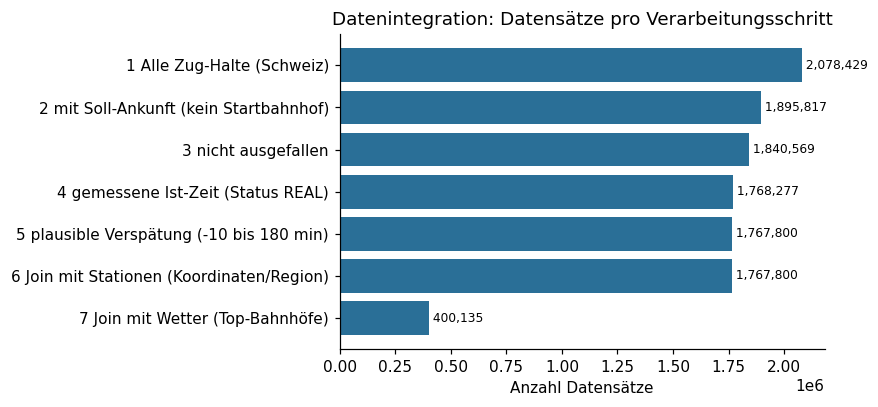

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(trichter["schritt"][::-1], trichter["datensaetze"][::-1], color="#2a6f97")
for y, v in enumerate(trichter["datensaetze"][::-1]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8)
ax.set_xlabel("Anzahl Datensätze")
ax.set_title("Datenintegration: Datensätze pro Verarbeitungsschritt")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "02_integration_trichter.png", dpi=200); plt.show()

Welche Haltestellen aus den Ist-Daten fanden **keinen Partner** in den Stammdaten?

In [5]:
display(pd.read_sql("""
    SELECT h.bpuic, h.haltestelle, COUNT(*) AS halte
    FROM halte h LEFT JOIN stationen s ON s.bpuic = h.bpuic
    WHERE s.bpuic IS NULL
    GROUP BY h.bpuic, h.haltestelle ORDER BY halte DESC LIMIT 10""", conn))

,bpuic,haltestelle,halte


## 3. Analysetabelle erstellen
Duplikate (gleiche Fahrt, gleicher Tag, gleiche Haltestelle) werden mit `ROW_NUMBER()` entfernt.

In [6]:
conn.executescript("""
DROP TABLE IF EXISTS analyse;
CREATE TABLE analyse AS
SELECT betriebstag, fahrt_id, betreiber, zugtyp, linie, bpuic, bahnhof, kanton, region, lat, lon,
       ankunft_soll, an_delay_min, temperatur, niederschlag, schneefall, wind
FROM (
    SELECT h.betriebstag, h.fahrt_id, h.betreiber, h.zugtyp, h.linie, h.bpuic,
           s.name AS bahnhof, s.kanton, s.region, s.lat, s.lon,
           h.ankunft_soll, h.an_delay_min,
           w.temperatur, w.niederschlag, w.schneefall, w.wind,
           ROW_NUMBER() OVER (PARTITION BY h.betriebstag, h.fahrt_id, h.bpuic ORDER BY h.ankunft_soll) AS rn
    FROM halte h
    JOIN stationen s ON s.bpuic = h.bpuic
    JOIN wetter   w ON w.bpuic = h.bpuic AND w.zeit = strftime('%Y-%m-%d %H:00', h.ankunft_soll)
    WHERE h.ankunft_soll IS NOT NULL AND h.faellt_aus = 0 AND h.an_status = 'REAL'
      AND h.an_delay_min BETWEEN -10 AND 180
)
WHERE rn = 1;
CREATE INDEX IF NOT EXISTS idx_analyse_bpuic ON analyse(bpuic);
""")
n_analyse = conn.execute("SELECT COUNT(*) FROM analyse").fetchone()[0]
print(f"Analysetabelle: {n_analyse:,} Zeilen  (entfernte Duplikate: {trichter['datensaetze'].iloc[-1] - n_analyse:,})")
display(pd.read_sql("SELECT * FROM analyse LIMIT 5", conn))

Analysetabelle: 400,135 Zeilen  (entfernte Duplikate: 0)


,betriebstag,fahrt_id,betreiber,zugtyp,linie,bpuic,bahnhof,kanton,region,lat,lon,ankunft_soll,an_delay_min,temperatur,niederschlag,schneefall,wind
0,2026-10-14,80:800693:3040:000,DB Regio,RE,RE3,8503424,Schaffhausen,SH,Deutschschweiz,47.698282,8.632756,2026-10-14 05:54:00,1.28,10.8,0.0,0.0,4.0
1,2026-10-14,80:800693:3041:000,DB Regio,RE,RE3,8503424,Schaffhausen,SH,Deutschschweiz,47.698282,8.632756,2026-10-14 06:14:00,0.28,10.2,0.0,0.0,3.6
2,2026-10-14,80:800693:3042:000,DB Regio,RE,RE3,8503424,Schaffhausen,SH,Deutschschweiz,47.698282,8.632756,2026-10-14 06:58:00,0.60,10.2,0.0,0.0,3.6
3,2026-10-14,80:800693:3043:000,DB Regio,RE,RE3,8503424,Schaffhausen,SH,Deutschschweiz,47.698282,8.632756,2026-10-14 06:58:00,2.00,10.2,0.0,0.0,3.6
4,2026-10-14,80:800693:3044:000,DB Regio,RE,RE3,8503424,Schaffhausen,SH,Deutschschweiz,47.698282,8.632756,2026-10-14 07:58:00,1.95,10.3,0.0,0.0,2.7


In [7]:
display(pd.read_sql("""
    SELECT region, COUNT(DISTINCT bpuic) AS bahnhoefe, COUNT(*) AS ankuenfte,
           ROUND(AVG(an_delay_min), 2) AS mittlere_verspaetung_min,
           ROUND(100.0 * AVG(an_delay_min >= 3), 1) AS anteil_verspaetet_prozent
    FROM analyse GROUP BY region ORDER BY ankuenfte DESC""", conn))

,region,bahnhoefe,ankuenfte,mittlere_verspaetung_min,anteil_verspaetet_prozent
0,Deutschschweiz,78,321461,0.75,5.8
1,Romandie,17,63536,0.77,8.8
2,Tessin,5,15138,0.89,7.1
